In [ ]:
# Postponed annotations apply notebook-wide (IPython propagates __future__
# flags), so they are declared once in the first cell as Ruff F404 requires.
from __future__ import annotations

from pathlib import Path
import sys
import math
import re
import json
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Workbook cleaning below is intentionally preserved; only its physical setup changes.
WORKBOOK_PATH = Path("C:\\Pasta_do_Jota\\TCC\\Estufa convec\u00e7\u00e3o - Borra de caf\u00e9.xlsx")
BED_DEPTH_M = 0.01
DISH_RADIUS_M = 0.025  # Provisional dish/bed radius, not a measured bean radius.
DISH_DIAMETER_M = 2.0 * DISH_RADIUS_M
T0_K = 298.15
T_AIR_K = 343.15
AIR_TEMPERATURE_K = T_AIR_K  # Kept for the preserved workbook parser.
TIME_SCALE_S = 240.0 * 60.0
DIAMETER_REFERENCE_M = 450e-6
SPEED_REFERENCE_M_S = 0.22
D_REF_M2_S = 1e-7
LATENT_HEAT_J_KG = 2_261_000.0
PRODUCT_DENSITY_KG_M3 = 1081.0
PRODUCT_CP_J_KG_K = 600.0
PRODUCT_K_W_M_K = 0.02
UNIVERSAL_GAS_CONSTANT_J_MOL_K = 8.31446261815324
DTYPE = torch.float64
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TRAINING_SEED = 42
TRAINING_STEPS = 50
COLLOCATION_COUNT = 128
RUN_TRAINING = True
EXPORT_DIFFUSIVITY = True
EXPORT_DIRECTORY = Path("src/training_results")

# Tabulated air values are used as supplied at 60 C, 1 atm. Cp is interpolated
# linearly between 320 K and 340 K at the correlation's 333.15 K property point.
AIR_PROPERTY_TEMPERATURE_K = 333.15
MU_AIR_PA_S = 1.999e-5
RHO_AIR_KG_M3 = 1.060
K_AIR_W_M_K = 0.02880
CP_AIR_320_K_J_KG = 1007.0
CP_AIR_340_K_J_KG = 1009.0
CP_AIR_J_KG_K = CP_AIR_320_K_J_KG + (
    AIR_PROPERTY_TEMPERATURE_K - 320.0
) * (CP_AIR_340_K_J_KG - CP_AIR_320_K_J_KG) / 20.0
PR_AIR = MU_AIR_PA_S * CP_AIR_J_KG_K / K_AIR_W_M_K
FO_REF = D_REF_M2_S * TIME_SCALE_S / BED_DEPTH_M**2
FO_HEAT = (
    PRODUCT_K_W_M_K * TIME_SCALE_S
    / (PRODUCT_DENSITY_KG_M3 * PRODUCT_CP_J_KG_K * BED_DEPTH_M**2)
)
NU_AIR_M2_S = MU_AIR_PA_S / RHO_AIR_KG_M3  # Kinematic viscosity, m2/s.
RE_AIR = SPEED_REFERENCE_M_S * DISH_DIAMETER_M / NU_AIR_M2_S
NUSSELT_AIR_REF = 0.664 * RE_AIR**0.5 * PR_AIR**(1/3)  # Dimensionless, not viscosity.
GAMMA = T0_K / (T_AIR_K - T0_K)
AIR_PROPERTY_SOURCES = {
    "dynamic_viscosity": "https://www.engineeringtoolbox.com/air-absolute-kinematic-viscosity-d_601.html",
    "density": "https://www.engineeringtoolbox.com/air-density-specific-weight-d_600.html",
    "thermal_conductivity_and_heat_capacity": "https://www.engineeringtoolbox.com/air-properties-viscosity-conductivity-heat-capacity-d_1509.html",
    "heat_capacity_table": "https://www.engineeringtoolbox.com/air-specific-heat-capacity-d_705.html",
}
PHYSICAL_CONSTANTS = {
    "bed_depth_m": BED_DEPTH_M,
    "dish_radius_m": DISH_RADIUS_M,
    "dish_diameter_m": DISH_DIAMETER_M,
    "t0_k": T0_K,
    "t_air_k": T_AIR_K,
    "time_scale_s": TIME_SCALE_S,
    "diameter_reference_m": DIAMETER_REFERENCE_M,
    "speed_reference_m_s": SPEED_REFERENCE_M_S,
    "d_ref_m2_s": D_REF_M2_S,
    "latent_heat_j_kg": LATENT_HEAT_J_KG,
    "product_density_kg_m3": PRODUCT_DENSITY_KG_M3,
    "product_cp_j_kg_k": PRODUCT_CP_J_KG_K,
    "product_k_w_m_k": PRODUCT_K_W_M_K,
    "mu_air_pa_s": MU_AIR_PA_S,
    "rho_air_kg_m3": RHO_AIR_KG_M3,
    "k_air_w_m_k": K_AIR_W_M_K,
    "cp_air_j_kg_k": CP_AIR_J_KG_K,
    "nu_air_m2_s": NU_AIR_M2_S,
    "pr_air": PR_AIR,
    "fo_ref": FO_REF,
    "fo_heat": FO_HEAT,
    "gamma": GAMMA,
}

# Tolerance is expressed in bulk moisture-ratio units for validation plots.
ACCURACY_TOLERANCE_MR = 0.05
if not math.isfinite(ACCURACY_TOLERANCE_MR) or ACCURACY_TOLERANCE_MR <= 0:
    raise ValueError("ACCURACY_TOLERANCE_MR must be finite and positive.")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__, "device:", DEVICE)
print("All differentiable model tensors use float64 on this device.")
print(f"Fo_ref={FO_REF:.6g}; Fo_heat={FO_HEAT:.6g}; gamma={GAMMA:.6g}")
print(
    "Air at 333.15 K / 1 atm (Engineering ToolBox): "
    f"mu={MU_AIR_PA_S:g} Pa s, rho={RHO_AIR_KG_M3:g} kg/m3, kinetic viscosity={NU_AIR_M2_S:g} m2/s, "
    f"k={K_AIR_W_M_K:g} W/(m K), interpolated cp={CP_AIR_J_KG_K:.3f} J/(kg K)"
)
print("Air-property table sources:")
for property_name, source_url in AIR_PROPERTY_SOURCES.items():
    print(f"  {property_name}: {source_url}")
print(
    f"Prantl number={PR_AIR:.3f}"
)
Speeds = [0.22, 0.48]
for speed in Speeds:
    Re = speed * DISH_DIAMETER_M / NU_AIR_M2_S
    Nu = 0.664 * Re**0.5 * PR_AIR**(1/3)
    h = Nu * K_AIR_W_M_K / DISH_DIAMETER_M
    Bi = h * BED_DEPTH_M / PRODUCT_K_W_M_K
    print(f"At speed {speed} m/s: Re={Re:.3f}, Nu={Nu:.3f}, h={h:.3f} W/(m2 K), Bi={Bi:.3f}")



Python: c:\Users\pushe\anaconda3\envs\finadv\python.exe
PyTorch: 2.9.0+cu126 device: cuda
All differentiable model tensors use float64 on this device.
Fo_ref=144; Fo_heat=4.44033; gamma=6.62556
Air at 333.15 K / 1 atm (Engineering ToolBox): mu=1.999e-05 Pa s, rho=1.06 kg/m3, kinetic viscosity=1.88585e-05 m2/s, k=0.0288 W/(m K), interpolated cp=1008.315 J/(kg K)
Air-property table sources:
  dynamic_viscosity: https://www.engineeringtoolbox.com/air-absolute-kinematic-viscosity-d_601.html
  density: https://www.engineeringtoolbox.com/air-density-specific-weight-d_600.html
  thermal_conductivity_and_heat_capacity: https://www.engineeringtoolbox.com/air-properties-viscosity-conductivity-heat-capacity-d_1509.html
  heat_capacity_table: https://www.engineeringtoolbox.com/air-specific-heat-capacity-d_705.html
Prantl number=0.700
At speed 0.22 m/s: Re=583.292, Nu=14.238, h=8.201 W/(m2 K), Bi=4.101
At speed 0.48 m/s: Re=1272.636, Nu=21.031, h=12.114 W/(m2 K), Bi=6.057


In [ ]:
torch.__version__

'2.9.0+cu126'

In [10]:
def parse_drying_workbook(
    sheets: dict[str, pd.DataFrame],
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Parse repeated sample blocks while retaining source values and flags.

    Sheet names encode air speed in m/s; diameter labels use micrometres.
    Workbook times and masses are minutes and grams, converted to SI in
    the returned tables. Source row numbers remain one-based for auditing.
    """
    experiment_records = []
    observation_records = []
    expected_headers = ["borra +B", "m borra", "u", "adm", "tx"]
    for sheet_name, raw in sheets.items():
        speed_match = re.fullmatch(r"(\d+(?:[.,]\d+)?)ms", sheet_name.strip())
        if speed_match is None:
            raise ValueError(f"Unrecognized air-speed sheet: {sheet_name}")
        speed = float(speed_match.group(1).replace(",", "."))
        if speed <= 0:
            raise ValueError("Air speed must be positive.")
        labels = raw.iloc[:, 0].astype(str).str.strip()
        header_rows = raw.index[labels.eq("Tempo")].tolist()
        dry_rows = raw.index[labels.eq("Mseca")].tolist()
        if len(header_rows) != 1 or len(dry_rows) != 1:
            raise ValueError(
                f"Expected one Tempo and one Mseca row in {sheet_name}."
            )
        header_row, dry_row = header_rows[0], dry_rows[0]
        if header_row < 4 or dry_row <= header_row:
            raise ValueError(
                f"Invalid header/dry-mass layout in {sheet_name}."
            )
        numeric_time = pd.to_numeric(raw.iloc[:, 0], errors="coerce")
        time_rows = raw.index[
            (raw.index > header_row)
            & (raw.index < dry_row)
            & numeric_time.notna()
        ]
        times_min = numeric_time.loc[time_rows].to_numpy(dtype=float)
        if (
            not len(times_min)
            or not np.isfinite(times_min).all()
            or (times_min < 0).any()
        ):
            raise ValueError(f"Invalid measurement times in {sheet_name}.")
        if (
            len(np.unique(times_min)) != len(times_min)
            or not (np.diff(times_min) > 0).all()
        ):
            raise ValueError(
                f"Times must be unique and increasing in {sheet_name}."
            )
        # A diameter heading carries forward across its replicate blocks.
        diameter_m = None
        for start in range(1, raw.shape[1], 5):
            if start + 4 >= raw.shape[1]:
                raise ValueError(f"Incomplete sample block in {sheet_name}.")
            headers = (
                raw.iloc[header_row, start:start + 5]
                .astype(str)
                .str.strip()
                .tolist()
            )
            if headers != expected_headers:
                raise ValueError(
                    f"Unexpected sample headers in {sheet_name}: {headers}"
                )
            diameter_label = raw.iloc[header_row - 4, start]
            if pd.notna(diameter_label):
                match = re.fullmatch(
                    r"(\d+(?:[.,]\d+)?)\s*(?:um|µm|μm)",
                    str(diameter_label).strip(),
                )
                if match is None:
                    raise ValueError(
                        f"Invalid diameter label: {diameter_label}"
                    )
                diameter_m = float(match.group(1).replace(",", ".")) * 1e-6
            if diameter_m is None or diameter_m <= 0:
                raise ValueError("Each sample must have a positive diameter.")
            replicate_value = float(raw.iloc[header_row - 3, start])
            if (
                not np.isfinite(replicate_value)
                or replicate_value < 1
                or not replicate_value.is_integer()
            ):
                raise ValueError("Replicate must be a positive integer.")
            replicate = int(replicate_value)
            tare_g = float(raw.iloc[header_row - 2, start])
            dry_g = float(raw.iloc[dry_row, start + 1])
            values = raw.loc[time_rows, raw.columns[start:start + 5]].apply(
                pd.to_numeric, errors="coerce"
            )
            values.columns = [
                "total_mass_g",
                "sample_mass_g",
                "u_source",
                "adm_source",
                "tx_source",
            ]
            initial_positions = np.flatnonzero(times_min == 0)
            if len(initial_positions) != 1:
                raise ValueError("Every curve needs a measurement at t=0.")
            initial_g = float(
                values.iloc[initial_positions[0]]["sample_mass_g"]
            )
            if (
                not np.isfinite([tare_g, dry_g, initial_g]).all()
                or tare_g < 0
                or not 0 < dry_g < initial_g
            ):
                raise ValueError(
                    f"Invalid tare, dry or initial mass in {sheet_name}, "
                    f"block {start}."
                )
            # u uses initial wet sample mass, not current or dry mass.
            # Dividing by initial_u then gives the normalized moisture adm.
            initial_u = (initial_g - dry_g) / initial_g
            condition_id = f"v{speed:g}_d{diameter_m * 1e6:g}"
            experiment_id = f"{condition_id}_r{replicate}"
            experiment_records.append(
                {
                    "experiment_id": experiment_id,
                    "condition_id": condition_id,
                    "replicate": replicate,
                    "particle_diameter_m": diameter_m,
                    "air_speed_m_s": speed,
                    "bed_depth_m": BED_DEPTH_M,
                    "air_temperature_K": AIR_TEMPERATURE_K,
                    "tare_mass_kg": tare_g / 1000,
                    "dry_mass_kg": dry_g / 1000,
                    "initial_sample_mass_kg": initial_g / 1000,
                    "initial_u": initial_u,
                    "ms_source_g": raw.iloc[header_row - 1, start],
                    "source_sheet": sheet_name,
                }
            )
            previous_mass = None
            for position, (source_index, row) in enumerate(values.iterrows()):
                mass_g = float(row["sample_mass_g"])
                total_g = float(row["total_mass_g"])
                valid_mass = np.isfinite(mass_g) and mass_g >= dry_g
                u = (
                    (mass_g - dry_g) / initial_g
                    if np.isfinite(mass_g)
                    else np.nan
                )
                adm = u / initial_u
                # Flags are diagnostic, not blanket exclusions: mass increases
                # and source-formula mismatches remain usable observations.
                flags = []
                if not np.isfinite(mass_g):
                    flags.append("missing_mass")
                elif mass_g < dry_g:
                    flags.append("below_dry_mass")
                if np.isfinite(mass_g):
                    if (
                        previous_mass is not None
                        and mass_g > previous_mass + 1e-8
                    ):
                        flags.append("mass_increase")
                    previous_mass = mass_g
                if (
                    np.isfinite(total_g)
                    and np.isfinite(mass_g)
                    and not np.isclose(
                        total_g - tare_g, mass_g, atol=1e-6, rtol=0
                    )
                ):
                    flags.append("tare_mismatch")
                for source_column, computed in [
                    ("u_source", u),
                    ("adm_source", adm),
                ]:
                    source_value = float(row[source_column])
                    if (
                        np.isfinite(source_value)
                        and np.isfinite(computed)
                        and not np.isclose(
                            source_value, computed, atol=1e-6, rtol=1e-5
                        )
                    ):
                        flags.append(f"{source_column}_mismatch")
                time_s = times_min[position] * 60
                # Workbook tx is adm/time_min, not a moisture derivative.
                legacy_tx = (
                    adm / times_min[position]
                    if times_min[position] > 0
                    else np.nan
                )
                observation_records.append(
                    {
                        "experiment_id": experiment_id,
                        "time_s": time_s,
                        "total_mass_kg": total_g / 1000,
                        "sample_mass_kg": mass_g / 1000,
                        "u_source": row["u_source"],
                        "adm_source": row["adm_source"],
                        "tx_source": row["tx_source"],
                        "u_recomputed": u,
                        "adm_recomputed": adm,
                        "legacy_adm_per_min": legacy_tx,
                        # Missing/sub-dry masses and tare errors block targets.
                        "target_available": bool(
                            valid_mass and "tare_mismatch" not in flags
                        ),
                        "quality_flags": ";".join(flags),
                        "source_row": int(source_index) + 1,
                    }
                )
    experiments = pd.DataFrame(experiment_records)
    observations = pd.DataFrame(observation_records)
    if experiments.empty or experiments["experiment_id"].duplicated().any():
        raise ValueError("Experiment IDs must be nonempty and unique.")
    if observations.duplicated(["experiment_id", "time_s"]).any():
        raise ValueError("Observation keys must be unique.")
    return experiments, observations


raw_sheets = pd.read_excel(WORKBOOK_PATH, sheet_name=None, header=None)
experiments, observations = parse_drying_workbook(raw_sheets)
print(
    f"{len(experiments)} experiments; "
    f"{len(observations)} scheduled observations; "
    f"{observations['target_available'].sum()} usable moisture targets"
)
print(
    observations.loc[observations["quality_flags"].ne(""), "quality_flags"]
    .value_counts()
    .to_string()
)


24 experiments; 576 scheduled observations; 560 usable moisture targets
quality_flags
mass_increase     22
missing_mass      15
below_dry_mass     1


,experiment_id,time_s,total_mass_kg,sample_mass_kg,u_source,adm_source,tx_source,u_recomputed,adm_recomputed,legacy_adm_per_min,target_available,quality_flags,source_row
0,v0.22_d610_r1,0.0,0.022331,0.008583,0.488442,1.000000,NaN,0.488442,1.000000,NaN,True,,7
1,v0.22_d610_r1,60.0,0.022331,0.008583,0.488442,1.000000,1.000000,0.488442,1.000000,1.000000,True,,8
2,v0.22_d610_r1,120.0,0.022331,0.008583,0.488454,1.000024,0.500012,0.488454,1.000024,0.500012,True,mass_increase,9
3,v0.22_d610_r1,180.0,0.022319,0.008570,0.487009,0.997066,0.332355,0.487009,0.997066,0.332355,True,,10
4,v0.22_d610_r1,240.0,0.022274,0.008526,0.481859,0.986523,0.246631,0.481859,0.986523,0.246631,True,,11
5,v0.22_d610_r1,300.0,0.022253,0.008505,0.479412,0.981513,0.196303,0.479412,0.981513,0.196303,True,,12
6,v0.22_d610_r1,600.0,0.022091,0.008343,0.460491,0.942775,0.094277,0.460491,0.942775,0.094277,True,,13
7,v0.22_d610_r1,900.0,0.021910,0.008162,0.439390,0.899575,0.059972,0.439390,0.899575,0.059972,True,,14
8,v0.22_d610_r1,1200.0,0.021739,0.007991,0.419467,0.858785,0.042939,0.419467,0.858785,0.042939,True,,15
9,v0.22_d610_r1,1500.0,0.021573,0.007825,0.400184,0.819307,0.032772,0.400184,0.819307,0.032772,True,,16


Workbook tx agrees with adm / time_min: True


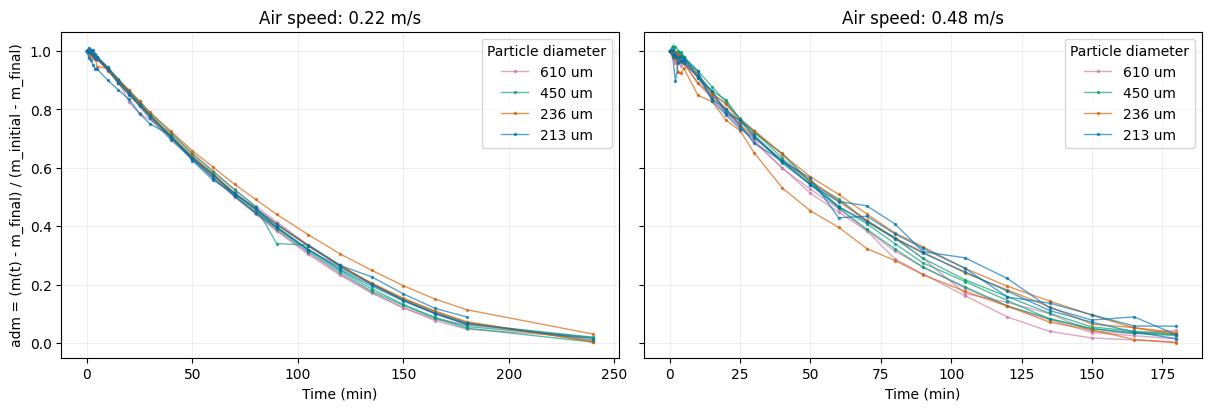

In [11]:
# display(experiments.head())
# matplotlib.pyplot is imported once as plt in the setup cell.
display(observations.head(10))

training_view = observations.merge(
    experiments, on="experiment_id", validate="many_to_one"
)

figure, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharey=True, constrained_layout=True
)
colors = dict(
    zip(
        sorted(experiments["particle_diameter_m"].unique()),
        ["#0072B2", "#D55E00", "#009E73", "#CC79A7"],
    )
)
for axis, speed in zip(axes, sorted(experiments["air_speed_m_s"].unique())):
    for experiment_id, curve in training_view.loc[
        training_view["air_speed_m_s"].eq(speed)
    ].groupby("experiment_id", sort=False):
        diameter = curve["particle_diameter_m"].iloc[0]
        available = curve["target_available"]
        axis.plot(
            curve.loc[available, "time_s"] / 60,
            curve.loc[available, "adm_recomputed"],
            color=colors[diameter],
            alpha=0.65,
            linewidth=1,
            marker=".",
            markersize=3,
            label=f"{diameter * 1e6:.0f} um"
            if curve["replicate"].iloc[0] == 1
            else None,
        )
    axis.set(title=f"Air speed: {speed:g} m/s", xlabel="Time (min)")
    axis.grid(alpha=0.2)
    axis.legend(title="Particle diameter")
axes[0].set_ylabel("adm = (m(t) - m_final) / (m_initial - m_final)")
# plt.show()

legacy_pairs = observations[["tx_source", "legacy_adm_per_min"]].dropna()
print(
    "Workbook tx agrees with adm / time_min:",
    np.allclose(
        legacy_pairs["tx_source"],
        legacy_pairs["legacy_adm_per_min"],
        rtol=1e-5,
        atol=1e-6,
    ),
)


In [12]:
# Postponed annotations and json are provided by the setup cell (cell 0).
from copy import deepcopy
import math
import os
from pathlib import Path
import shutil
import tempfile

from torch import nn


class DryingPINN(nn.Module):
    """Coupled state PINN and four-parameter positive diffusivity law."""

    def __init__(self) -> None:
        super().__init__()
        # A linear projection permits states beyond the hidden Tanh range.
        layer_sizes = (4, 64, 32, 32, 32, 64)
        layers: list[nn.Module] = []
        for input_size, output_size in zip(layer_sizes[:-1], layer_sizes[1:]):
            layers.append(nn.Linear(input_size, output_size))
            layers.append(nn.Tanh())
        layers.append(nn.Linear(layer_sizes[-1], 2))
        self.network = nn.Sequential(*layers)
        # Softplus makes theta0 and theta3 strictly positive without clipping
        # gradients; theta1/theta2 remain unconstrained log-log exponents.
        self.raw_theta0 = nn.Parameter(torch.tensor(0.0, dtype=DTYPE))
        self.theta1 = nn.Parameter(torch.tensor(0.0, dtype=DTYPE))
        self.theta2 = nn.Parameter(torch.tensor(0.0, dtype=DTYPE))
        self.raw_theta3 = nn.Parameter(torch.tensor(0.0, dtype=DTYPE))
        self.to(device=DEVICE, dtype=DTYPE)

    @property
    def theta0(self) -> torch.Tensor:
        """Return the positive pre-exponential coefficient."""
        return torch.nn.functional.softplus(self.raw_theta0)

    @property
    def theta3(self) -> torch.Tensor:
        """Return the positive dimensionless thermal activation coefficient."""
        return torch.nn.functional.softplus(self.raw_theta3)

    @property
    def learned_theta(self) -> dict[str, torch.Tensor]:
        """Expose physical coefficients while retaining raw optimizer values."""
        return {
            "theta0": self.theta0,
            "theta1": self.theta1,
            "theta2": self.theta2,
            "theta3": self.theta3,
        }

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        """Predict local excess moisture and temperature with hard ICs."""
        _validate_coordinate_tensor(inputs)
        parameter = next(self.network.parameters())
        if inputs.device != parameter.device:
            raise ValueError("Coordinates and model parameters must share a device.")
        if inputs.dtype != parameter.dtype:
            raise ValueError("Coordinates and model parameters must share a dtype.")
        raw_fields = self.network(inputs)
        time_star = inputs[:, 1:2]
        # At time zero, rho*=1 and T*=0 exactly for every depth and run.
        return torch.cat(
            (1.0 + time_star * raw_fields[:, 0:1], time_star * raw_fields[:, 1:2]),
            dim=1,
        )

    def diffusivity_star(
        self, inputs: torch.Tensor, temperature_star: torch.Tensor
    ) -> torch.Tensor:
        """Evaluate dimensionless Dw while retaining gradients through T*."""
        _validate_coordinate_tensor(inputs)
        parameter = next(self.network.parameters())
        if inputs.device != parameter.device:
            raise ValueError("Coordinates and model parameters must share a device.")
        if inputs.dtype != parameter.dtype:
            raise ValueError("Coordinates and model parameters must share a dtype.")
        if temperature_star.device != inputs.device:
            raise ValueError("Temperature and inputs must share a device.")
        if temperature_star.dtype != inputs.dtype:
            raise ValueError("Temperature and inputs must share a dtype.")
        if temperature_star.shape != (inputs.shape[0], 1):
            raise ValueError("Temperature must have shape (batch, 1).")
        if not torch.isfinite(temperature_star).all():
            raise ValueError("Temperature evaluations must be finite.")
        gamma = T0_K / (T_AIR_K - T0_K)
        denominator = temperature_star + gamma
        absolute_temperature = T0_K + (T_AIR_K - T0_K) * temperature_star
        if torch.any(denominator <= 0.0) or torch.any(absolute_temperature <= 0.0):
            raise ValueError("Invalid temperature denominator or absolute temperature.")
        theta = self.learned_theta
        d_star = inputs[:, 2:3]
        v_star = inputs[:, 3:4]
        if torch.any(d_star <= 0.0) or torch.any(v_star <= 0.0):
            raise ValueError("Dimensionless diameter and speed must be positive.")
        values = (
            theta["theta0"]
            * d_star.pow(theta["theta1"])
            * v_star.pow(theta["theta2"])
            * torch.exp(-theta["theta3"] / denominator)
        )
        if not torch.isfinite(values).all():
            raise FloatingPointError("Nonfinite diffusivity evaluation.")
        if torch.any(values <= 0.0):
            raise FloatingPointError("Diffusivity underflowed to a nonpositive value.")
        return values


def _validate_coordinate_tensor(inputs: torch.Tensor) -> None:
    """Reject malformed or nonfinite coordinate tensors at model boundaries."""
    if not isinstance(inputs, torch.Tensor) or inputs.ndim != 2:
        raise TypeError("Coordinates must be a rank-two torch.Tensor.")
    if inputs.shape[1] != 4:
        raise ValueError("Coordinates must have columns [z*, t*, d*, v*].")
    if not inputs.is_floating_point():
        raise TypeError("Coordinates must use a floating-point dtype.")
    if not torch.isfinite(inputs).all():
        raise ValueError("Coordinates must be finite.")


def _autograd_derivative(
    values: torch.Tensor,
    coordinates: torch.Tensor,
    column: int,
    *,
    create_graph: bool,
) -> torch.Tensor:
    """Differentiate one field against one coordinate, preserving the graph."""
    derivative = torch.autograd.grad(
        values.sum(),
        coordinates,
        create_graph=create_graph,
        retain_graph=True,
        allow_unused=False,
    )[0]
    return derivative[:, column : column + 1]


def physics_residuals(
    model: DryingPINN,
    coordinates: torch.Tensor,
    fo_ref: float,
    fo_heat: float,
) -> dict[str, torch.Tensor]:
    """Evaluate conservative variable-D mass and coupled conduction residuals."""
    _validate_coordinate_tensor(coordinates)
    if not coordinates.requires_grad:
        coordinates = coordinates.detach().clone().requires_grad_(True)
    predictions = model(coordinates)
    moisture = predictions[:, 0:1]
    temperature = predictions[:, 1:2]
    moisture_gradient = _autograd_derivative(
        moisture, coordinates, 0, create_graph=True
    )
    moisture_time = _autograd_derivative(moisture, coordinates, 1, create_graph=True)
    temperature_time = _autograd_derivative(
        temperature, coordinates, 1, create_graph=True
    )
    temperature_gradient = _autograd_derivative(
        temperature, coordinates, 0, create_graph=True
    )
    temperature_curvature = _autograd_derivative(
        temperature_gradient, coordinates, 0, create_graph=True
    )
    diffusivity = model.diffusivity_star(coordinates, temperature)
    mass_flux_gradient = _autograd_derivative(
        diffusivity * moisture_gradient, coordinates, 0, create_graph=True
    )
    return {
        "mass": moisture_time - fo_ref * mass_flux_gradient,
        "heat": temperature_time - fo_heat * temperature_curvature,
        "moisture": moisture,
        "temperature": temperature,
    }


def boundary_residuals(
    model: DryingPINN,
    base_coordinates: torch.Tensor,
    surface_coordinates: torch.Tensor,
    rate_star: torch.Tensor,
    bi: torch.Tensor,
    evaporation_number: torch.Tensor,
) -> dict[str, torch.Tensor]:
    """Evaluate signed no-flux and measured-rate surface balances."""
    for coordinates in (base_coordinates, surface_coordinates):
        _validate_coordinate_tensor(coordinates)
    if base_coordinates.shape[1:] != surface_coordinates.shape[1:]:
        raise ValueError("Base and surface coordinates must have matching widths.")
    if not (
        base_coordinates.device
        == surface_coordinates.device
        == rate_star.device
        == bi.device
        == evaporation_number.device
    ):
        raise ValueError("Boundary tensors must share a device.")
    if not (
        base_coordinates.dtype
        == surface_coordinates.dtype
        == rate_star.dtype
        == bi.dtype
        == evaporation_number.dtype
    ):
        raise ValueError("Boundary tensors must share a dtype.")
    expected_shape = (surface_coordinates.shape[0], 1)
    if any(
        value.shape != expected_shape for value in (rate_star, bi, evaporation_number)
    ):
        raise ValueError("Boundary rates and groups must have shape (batch, 1).")
    if not all(
        torch.isfinite(value).all()
        for value in (
            rate_star,
            bi,
            evaporation_number,
            base_coordinates,
            surface_coordinates,
        )
    ):
        raise ValueError("Boundary inputs must be finite.")
    if torch.any(bi <= 0.0) or torch.any(evaporation_number < 0.0):
        raise ValueError("Bi must be positive and Ev cannot be negative.")
    base = base_coordinates.detach().clone().requires_grad_(True)
    surface = surface_coordinates.detach().clone().requires_grad_(True)
    base_fields = model(base)
    surface_fields = model(surface)
    base_moisture_gradient = _autograd_derivative(
        base_fields[:, 0:1], base, 0, create_graph=True
    )
    base_temperature_gradient = _autograd_derivative(
        base_fields[:, 1:2], base, 0, create_graph=True
    )
    surface_moisture_gradient = _autograd_derivative(
        surface_fields[:, 0:1], surface, 0, create_graph=True
    )
    surface_temperature_gradient = _autograd_derivative(
        surface_fields[:, 1:2], surface, 0, create_graph=True
    )
    diffusivity = model.diffusivity_star(surface, surface_fields[:, 1:2])
    fo_ref = PHYSICAL_CONSTANTS["fo_ref"]
    mass_residual = fo_ref * diffusivity * surface_moisture_gradient + rate_star
    heat_residual = (
        surface_temperature_gradient
        - bi * (1.0 - surface_fields[:, 1:2])
        + evaporation_number * rate_star
    )
    return {
        "base_mass": base_moisture_gradient,
        "base_heat": base_temperature_gradient,
        "surface_mass": mass_residual,
        "surface_heat": heat_residual,
    }


def build_physics_tables(
    curves: pd.DataFrame, constants: dict[str, float]
) -> pd.DataFrame:
    """Derive air/product groups and per-curve Ev from measured workbook masses."""
    required = {
        "experiment_id",
        "condition_id",
        "particle_diameter_m",
        "air_speed_m_s",
    }
    if not required.issubset(curves.columns):
        raise ValueError(
            f"Curve table missing columns: {sorted(required - set(curves))}"
        )
    records: list[dict[str, float | str]] = []
    for curve in curves.to_dict(orient="records"):
        velocity = float(curve["air_speed_m_s"])
        diameter = float(curve["particle_diameter_m"])
        if not math.isfinite(velocity) or velocity <= 0:
            raise ValueError("Air speed must be finite and positive.")
        if not math.isfinite(diameter) or diameter <= 0:
            raise ValueError("Particle diameter must be finite and positive.")
        if "initial_water_concentration_kg_m3" in curve:
            water_concentration = float(curve["initial_water_concentration_kg_m3"])
        else:
            water_mass = float(curve["initial_sample_mass_kg"]) - float(
                curve["dry_mass_kg"]
            )
            bed_volume = (
                math.pi * constants["dish_radius_m"] ** 2 * constants["bed_depth_m"]
            )
            water_concentration = water_mass / bed_volume
        if not math.isfinite(water_concentration) or water_concentration <= 0:
            raise ValueError("Initial excess-water concentration must be positive.")
        reynolds = velocity * constants["dish_diameter_m"] / constants["nu_air_m2_s"]
        if not math.isfinite(reynolds) or reynolds <= 0:
            raise ValueError("Reynolds number must be finite and positive.")
        nusselt = 0.664 * math.sqrt(reynolds) * constants["pr_air"] ** (1.0 / 3.0)
        h = nusselt * constants["k_air_w_m_k"] / constants["dish_diameter_m"]
        bi = h * constants["bed_depth_m"] / constants["product_k_w_m_k"]
        evaporation = (
            constants["latent_heat_j_kg"]
            * water_concentration
            * constants["bed_depth_m"] ** 2
            / (
                constants["product_k_w_m_k"]
                * constants["time_scale_s"]
                * (constants["t_air_k"] - constants["t0_k"])
            )
        )
        records.append(
            {
                "experiment_id": str(curve["experiment_id"]),
                "condition_id": str(curve["condition_id"]),
                "velocity_m_s": velocity,
                "particle_diameter_m": diameter,
                "water_concentration_kg_m3": water_concentration,
                "re": reynolds,
                "pr": constants["pr_air"],
                "nusselt": nusselt,
                "h_w_m2_k": h,
                "bi": bi,
                "ev": evaporation,
            }
        )
    result = pd.DataFrame(records)
    if result.empty or result["experiment_id"].duplicated().any():
        raise ValueError("Physics table needs unique, nonempty replicate curves.")
    numeric = result.select_dtypes(include=[np.number]).to_numpy()
    if not np.isfinite(numeric).all():
        raise ValueError("Derived physics table contains nonfinite values.")
    return result


def build_scheduled_intervals(observations: pd.DataFrame) -> pd.DataFrame:
    """Build signed secants only across consecutive valid scheduled endpoints."""
    required = {
        "experiment_id",
        "time_s",
        "adm_recomputed",
        "target_available",
    }
    if not required.issubset(observations.columns):
        raise ValueError(
            f"Observations missing columns: {sorted(required - set(observations))}"
        )
    intervals: list[dict[str, object]] = []
    for experiment_id, scheduled in observations.groupby("experiment_id", sort=True):
        ordered = scheduled.sort_values("time_s", kind="stable").reset_index(drop=True)
        times = ordered["time_s"].to_numpy(dtype=float)
        if not np.isfinite(times).all() or (np.diff(times) <= 0).any():
            raise ValueError(f"Scheduled times must increase for {experiment_id}.")
        available = ordered["target_available"].fillna(False).to_numpy(dtype=bool)
        mr = pd.to_numeric(ordered["adm_recomputed"], errors="coerce").to_numpy(
            dtype=float
        )
        available &= np.isfinite(mr)
        for left_index in range(len(ordered) - 1):
            right_index = left_index + 1
            if not (available[left_index] and available[right_index]):
                continue
            dt_star = (times[right_index] - times[left_index]) / TIME_SCALE_S
            signed_rate = -(mr[right_index] - mr[left_index]) / dt_star
            left = ordered.iloc[left_index]
            right = ordered.iloc[right_index]
            flags = str(right.get("quality_flags", ""))
            intervals.append(
                {
                    "experiment_id": str(experiment_id),
                    "left_time_s": float(times[left_index]),
                    "right_time_s": float(times[right_index]),
                    "mid_time_s": float((times[left_index] + times[right_index]) / 2.0),
                    "dt_star": float(dt_star),
                    "left_mr": float(mr[left_index]),
                    "right_mr": float(mr[right_index]),
                    "rate_star": float(signed_rate),
                    "mass_increase": bool(
                        "mass_increase" in flags or mr[right_index] > mr[left_index]
                    ),
                    "left_source_row": int(left.get("source_row", -1)),
                    "right_source_row": int(right.get("source_row", -1)),
                    "right_quality_flags": flags,
                }
            )
    frame = pd.DataFrame(intervals)
    if frame.empty:
        return pd.DataFrame(
            columns=[
                "experiment_id",
                "left_time_s",
                "right_time_s",
                "mid_time_s",
                "dt_star",
                "left_mr",
                "right_mr",
                "rate_star",
                "mass_increase",
                "left_source_row",
                "right_source_row",
                "right_quality_flags",
            ]
        )
    if not np.isfinite(frame["rate_star"].to_numpy(dtype=float)).all():
        raise ValueError("Measured-rate secants must be finite.")
    return frame


def equal_curve_weights(frame: pd.DataFrame, curve_column: str) -> np.ndarray:
    """Give each replicate equal total weight regardless of row count."""
    if frame.empty or curve_column not in frame:
        raise ValueError("Weighting requires nonempty rows with curve IDs.")
    identifiers = frame[curve_column].astype(str)
    curve_count = identifiers.nunique()
    per_curve_count = identifiers.groupby(identifiers).transform("size")
    weights = 1.0 / (curve_count * per_curve_count.to_numpy(dtype=float))
    if not np.isfinite(weights).all():
        raise ValueError("Curve weights must be finite.")
    return weights


def _as_tensor(
    values: np.ndarray | pd.Series, *, requires_grad: bool = False
) -> torch.Tensor:
    """Create float64 batches on the same device as the registered model."""
    tensor = torch.as_tensor(
        np.asarray(values, dtype=np.float64), dtype=DTYPE, device=DEVICE
    )
    return tensor.requires_grad_(requires_grad)


def _feature_matrix(
    frame: pd.DataFrame, *, time_column: str, depth_star: np.ndarray | float = 0.5
) -> torch.Tensor:
    """Normalize state coordinates while keeping positive condition ratios."""
    depths = np.broadcast_to(np.asarray(depth_star, dtype=float), len(frame))
    return _as_tensor(
        np.column_stack(
            [
                depths,
                frame[time_column].to_numpy(dtype=float) / TIME_SCALE_S,
                frame["particle_diameter_m"].to_numpy(dtype=float)
                / DIAMETER_REFERENCE_M,
                frame["air_speed_m_s"].to_numpy(dtype=float) / SPEED_REFERENCE_M_S,
            ]
        )
    )




In [13]:
def bulk_state_and_rate(
    model: DryingPINN,
    coordinates: torch.Tensor,
    *,
    depth_points: int = 50,
    compute_time_rate: bool = True,
) -> tuple[torch.Tensor, torch.Tensor | None]:
    """Return midpoint bulk moisture and true drying rate -d<rho*>/dt*.

    Model rows must be independent (as in DryingPINN's Linear/Tanh layers).
    Summing pointwise outputs then differentiating gives each row's partial
    time derivative; average those derivatives over depths exactly once.
    Detached coordinate copies keep caller feature gradients untouched;
    create_graph preserves rate-loss gradients to the model parameters.
    """
    _validate_coordinate_tensor(coordinates)
    if (
        isinstance(depth_points, bool)
        or not isinstance(depth_points, int)
        or depth_points < 1
    ):
        raise ValueError("depth_points must be a positive integer.")
    batch_size = coordinates.shape[0]
    z_midpoints = (
        torch.arange(depth_points, dtype=coordinates.dtype, device=coordinates.device)
        + 0.5
    ) / depth_points
    expanded = coordinates.detach().clone().repeat_interleave(depth_points, dim=0)
    expanded[:, 0] = z_midpoints.repeat(batch_size)
    expanded.requires_grad_(compute_time_rate)
    moisture = model(expanded)[:, 0:1].reshape(batch_size, depth_points)
    bulk_moisture = moisture.mean(dim=1, keepdim=True)
    if not compute_time_rate:
        return bulk_moisture, None
    time_derivative_by_depth = torch.autograd.grad(
        moisture.sum(),
        expanded,
        create_graph=True,
        retain_graph=True,
    )[0][:, 1:2].reshape(batch_size, depth_points)
    bulk_rate = -time_derivative_by_depth.mean(dim=1, keepdim=True)
    return bulk_moisture, bulk_rate


def build_training_batch(
    observations: pd.DataFrame,
    curves: pd.DataFrame,
    physics_tables: pd.DataFrame,
    *,
    collocation_count: int = 128,
    seed: int = TRAINING_SEED,
) -> dict[str, torch.Tensor]:
    """Build fully fixed data, rate, interior and boundary batches."""
    if collocation_count < 2:
        raise ValueError("At least two fixed interior collocation points are required.")
    intervals = build_scheduled_intervals(observations)
    if intervals.empty:
        raise ValueError("Training data have no usable adjacent rate intervals.")
    curve_ids = set(curves["experiment_id"].astype(str))
    intervals = intervals.loc[intervals["experiment_id"].isin(curve_ids)].copy()
    interval_curve_ids = set(intervals["experiment_id"].astype(str))
    missing_intervals = curve_ids - interval_curve_ids
    if missing_intervals:
        raise ValueError(
            "Training curves without valid adjacent rate intervals: "
            f"{sorted(missing_intervals)}"
        )
    if intervals.empty:
        raise ValueError("No rate intervals overlap selected training curves.")
    interval_view = intervals.merge(
        curves, on="experiment_id", validate="many_to_one"
    ).merge(
        physics_tables[["experiment_id", "bi", "ev"]],
        on="experiment_id",
        validate="many_to_one",
    )
    interval_view = interval_view.sort_values(
        ["experiment_id", "left_time_s"], kind="stable"
    ).reset_index(drop=True)
    observation_view = observations.loc[
        observations["experiment_id"].isin(curve_ids)
        & observations["target_available"].fillna(False)
    ].copy()
    observation_view["adm_recomputed"] = pd.to_numeric(
        observation_view["adm_recomputed"], errors="coerce"
    )
    observation_view = observation_view.loc[
        np.isfinite(observation_view["adm_recomputed"])
    ].merge(curves, on="experiment_id", validate="many_to_one")
    if observation_view.empty:
        raise ValueError("Training set has no usable bulk moisture observations.")
    rng = np.random.default_rng(seed)
    intervals_by_curve = {
        curve_id: rows.reset_index(drop=True)
        for curve_id, rows in interval_view.groupby("experiment_id", sort=True)
    }
    available_curves = sorted(intervals_by_curve)
    sampled_rows = []
    for curve_id in rng.choice(available_curves, size=collocation_count, replace=True):
        choices = intervals_by_curve[curve_id]
        selected = choices.iloc[int(rng.integers(len(choices)))].copy()
        lower = np.nextafter(
            float(selected["left_time_s"]), float(selected["right_time_s"])
        )
        upper = np.nextafter(
            float(selected["right_time_s"]), float(selected["left_time_s"])
        )
        selected["collocation_time_s"] = rng.uniform(lower, upper)
        sampled_rows.append(selected)
    collocation_frame = pd.DataFrame(sampled_rows).reset_index(drop=True)
    interior = _feature_matrix(
        collocation_frame,
        time_column="collocation_time_s",
        depth_star=rng.uniform(0.0, 1.0, collocation_count),
    )
    base = interior.detach().clone()
    base[:, 0] = 0.0
    data_features = _feature_matrix(observation_view, time_column="time_s")
    data_targets = _as_tensor(
        observation_view["adm_recomputed"].to_numpy(dtype=float)[:, None]
    )
    data_weights = _as_tensor(
        equal_curve_weights(observation_view, "experiment_id")[:, None]
    )
    rate_features = _feature_matrix(
        interval_view, time_column="mid_time_s", depth_star=1.0
    )
    rate_targets = _as_tensor(interval_view["rate_star"].to_numpy()[:, None])
    rate_weights = _as_tensor(
        equal_curve_weights(interval_view, "experiment_id")[:, None]
    )
    return {
        "interior": interior,
        "base": base,
        "data_features": data_features,
        "data_targets": data_targets,
        "data_weights": data_weights,
        "rate_features": rate_features,
        "rate_targets": rate_targets,
        "rate_weights": rate_weights,
        "surface_bi": _as_tensor(interval_view["bi"].to_numpy()[:, None]),
        "surface_ev": _as_tensor(interval_view["ev"].to_numpy()[:, None]),
    }


LOSS_WEIGHTS = {
    "data": 10.0,
    "rate": 1.0,
    "mass_pde": 1.0,
    "heat_pde": 1.0,
    "base_mass": 1.0,
    "base_heat": 1.0,
    "surface_mass": 1.0,
    "surface_heat": 1.0,
    "negative_moisture": 1.0,
}


def evaluate_loss_components(
    model: DryingPINN, batch: dict[str, torch.Tensor]
) -> tuple[dict[str, torch.Tensor], torch.Tensor]:
    """Compute curve-weighted data and signed-rate losses plus physics terms."""
    data_bulk, _ = bulk_state_and_rate(
        model, batch["data_features"], compute_time_rate=False
    )
    data_loss = ((data_bulk - batch["data_targets"]) ** 2 * batch["data_weights"]).sum()
    rate_points = batch["rate_features"].detach().clone().requires_grad_(True)
    _, rate_rate = bulk_state_and_rate(model, rate_points)
    rate_loss = ((rate_rate - batch["rate_targets"]) ** 2 * batch["rate_weights"]).sum()
    interior = physics_residuals(
        model,
        batch["interior"],
        PHYSICAL_CONSTANTS["fo_ref"],
        PHYSICAL_CONSTANTS["fo_heat"],
    )
    mass_loss = torch.mean(interior["mass"] ** 2)
    heat_loss = torch.mean(interior["heat"] ** 2)
    boundary = boundary_residuals(
        model,
        batch["base"],
        batch["rate_features"],
        batch["rate_targets"],
        batch["surface_bi"],
        batch["surface_ev"],
    )
    surface_moisture = model(batch["rate_features"])[:, 0:1]
    negative = (
        (torch.relu(-interior["moisture"]) ** 2).mean()
        + (torch.relu(-model(batch["base"])[:, 0:1]) ** 2).mean()
        + (torch.relu(-surface_moisture) ** 2 * batch["rate_weights"]).sum()
    )
    components = {
        "data": data_loss,
        "rate": rate_loss,
        "mass_pde": mass_loss,
        "heat_pde": heat_loss,
        "base_mass": torch.mean(boundary["base_mass"] ** 2),
        "base_heat": torch.mean(boundary["base_heat"] ** 2),
        "surface_mass": (
            boundary["surface_mass"] ** 2 * batch["rate_weights"]
        ).sum(),
        "surface_heat": (
            boundary["surface_heat"] ** 2 * batch["rate_weights"]
        ).sum(),
        "negative_moisture": negative,
    }
    for name, value in components.items():
        if not torch.isfinite(value):
            raise FloatingPointError(f"Nonfinite {name} loss.")
    total = sum(LOSS_WEIGHTS[name] * value for name, value in components.items())
    if not torch.isfinite(total):
        raise FloatingPointError("Nonfinite joint objective.")
    return components, total


def train_inverse_model(
    model: DryingPINN,
    batch: dict[str, torch.Tensor],
    *,
    steps: int = TRAINING_STEPS,
    learning_rate: float = 0.001,
) -> tuple[pd.DataFrame, int, int]:
    """Run fixed-batch full-batch L-BFGS and select the best finite step."""
    if isinstance(steps, bool) or not isinstance(steps, int) or steps <= 0:
        raise ValueError("L-BFGS outer steps must be a positive integer.")
    if learning_rate <= 0 or not math.isfinite(learning_rate):
        raise ValueError("L-BFGS learning rate must be finite and positive.")
    optimizer = torch.optim.LBFGS(
        model.parameters(),
        lr=learning_rate,
        max_iter=1,
        line_search_fn="strong_wolfe",
    )
    closure_count = 0
    history: list[dict[str, float | int]] = []
    selected_state = deepcopy(model.state_dict())
    selected_loss = math.inf
    selected_step = 0
    for outer_step in range(1, steps + 1):

        def closure() -> torch.Tensor:
            nonlocal closure_count
            closure_count += 1
            optimizer.zero_grad(set_to_none=True)
            _, objective = evaluate_loss_components(model, batch)
            objective.backward()
            gradients = [
                parameter.grad
                for parameter in model.parameters()
                if parameter.grad is not None
            ]
            if not gradients or not all(
                torch.isfinite(gradient).all() for gradient in gradients
            ):
                raise FloatingPointError(
                    "Joint state/constitutive gradients are invalid."
                )
            if not all(
                torch.isfinite(parameter).all() for parameter in model.parameters()
            ):
                raise FloatingPointError("Joint parameters became nonfinite.")
            return objective

        optimizer.step(closure)
        with torch.enable_grad():
            components, total = evaluate_loss_components(model, batch)
        row: dict[str, float | int] = {
            "outer_step": outer_step,
            "closure_evaluations": closure_count,
            "total_loss": float(total.detach().cpu()),
        }
        row.update(
            {
                f"loss_{name}": float(value.detach().cpu())
                for name, value in components.items()
            }
        )
        history.append(row)
        current_loss = row["total_loss"]
        if current_loss < selected_loss:
            selected_loss = current_loss
            selected_step = outer_step
            selected_state = deepcopy(model.state_dict())
    model.load_state_dict(selected_state)
    if not history or not np.isfinite(selected_loss):
        raise FloatingPointError("No finite accepted L-BFGS step was recorded.")
    return pd.DataFrame(history), closure_count, selected_step




In [14]:
def make_diffusivity_table(
    model: DryingPINN,
    curves: pd.DataFrame,
    *,
    depth_points: int = 31,
    time_points: int = 41,
) -> pd.DataFrame:
    """Evaluate per-run Dw and model-implied temperature over depth and time."""
    if depth_points < 2 or time_points < 2:
        raise ValueError("Diffusivity export grids need at least two points per axis.")
    z_values = np.linspace(0.0, 1.0, depth_points)
    t_values = np.linspace(0.0, 1.0, time_points)
    z_grid, t_grid = np.meshgrid(z_values, t_values, indexing="ij")
    records = []
    model.eval()
    model_parameter = next(model.parameters())
    with torch.enable_grad():
        for curve in curves.to_dict(orient="records"):
            input_values = np.column_stack(
                [
                    z_grid.ravel(),
                    t_grid.ravel(),
                    np.full(z_grid.size, curve["particle_diameter_m"])
                    / DIAMETER_REFERENCE_M,
                    np.full(z_grid.size, curve["air_speed_m_s"]) / SPEED_REFERENCE_M_S,
                ]
            )
            inputs = torch.as_tensor(
                input_values,
                dtype=model_parameter.dtype,
                device=model_parameter.device,
            )
            fields = model(inputs)
            diffusivity_star = model.diffusivity_star(inputs, fields[:, 1:2])
            local_temperature_k = T0_K + (T_AIR_K - T0_K) * fields[:, 1:2]
            values = (
                torch.cat(
                    (
                        fields,
                        local_temperature_k,
                        diffusivity_star,
                        D_REF_M2_S * diffusivity_star,
                    ),
                    dim=1,
                )
                .detach()
                .cpu()
                .numpy()
            )
            for index, row in enumerate(values):
                zi, ti = np.unravel_index(index, z_grid.shape)
                records.append(
                    {
                        "experiment_id": str(curve["experiment_id"]),
                        "condition_id": str(curve["condition_id"]),
                        "depth_star": float(z_values[zi]),
                        "depth_m": float(z_values[zi] * BED_DEPTH_M),
                        "time_star": float(t_values[ti]),
                        "time_s": float(t_values[ti] * TIME_SCALE_S),
                        "rho_star": float(row[0]),
                        "temperature_star_model": float(row[1]),
                        "temperature_k_model_implied": float(row[2]),
                        "diffusivity_star": float(row[3]),
                        "dw_m2_s": float(row[4]),
                    }
                )
    result = pd.DataFrame(records)
    numeric = result.select_dtypes(include=[np.number]).to_numpy()
    if not np.isfinite(numeric).all() or (result["dw_m2_s"] <= 0).any():
        raise FloatingPointError("Diffusivity export contains invalid values.")
    return result


def resolve_output_path(output_path: str | Path) -> Path:
    """Resolve relative run locations against the current notebook project root."""
    path = Path(output_path).expanduser()
    if path.is_absolute():
        return path.resolve()
    current = Path.cwd()
    project_root = current
    for candidate in (current, current.parent):
        if (candidate / "README.md").is_file() and (candidate / "notebooks").is_dir():
            project_root = candidate
            break
    return (project_root / path).resolve()


def export_strategy_a_run(
    *,
    model: DryingPINN,
    history: pd.DataFrame,
    diffusivity_tables: pd.DataFrame,
    output_path: str | Path,
    manifest: dict[str, object],
    selected_outer_step: int,
) -> Path:
    """Atomically publish strict-JSON and tabular artifacts without overwrites."""
    if history.empty or diffusivity_tables.empty:
        raise ValueError("Export requires nonempty history and diffusivity tables.")
    if not np.isfinite(history.select_dtypes(include=[np.number]).to_numpy()).all():
        raise ValueError("History contains nonfinite values.")
    if not np.isfinite(
        diffusivity_tables.select_dtypes(include=[np.number]).to_numpy()
    ).all():
        raise ValueError("Diffusivity tables contain nonfinite values.")
    destination = resolve_output_path(output_path)
    parent = destination.parent
    parent.mkdir(parents=True, exist_ok=True)
    if destination.exists():
        raise FileExistsError(f"Refusing to overwrite existing run: {destination}")
    staging = Path(tempfile.mkdtemp(prefix=".strategy_a_staging_", dir=str(parent)))
    try:
        history.to_csv(staging / "history.csv", index=False)
        diffusivity_tables.to_csv(staging / "diffusivity.csv", index=False)
        theta_values = {
            name: float(value.detach().cpu())
            for name, value in model.learned_theta.items()
        }
        theta_payload = {
            **theta_values,
            "gamma": T0_K / (T_AIR_K - T0_K),
            "equation": (
                "D_star=theta0*(d_star**theta1)*(v_star**theta2)"
                "*exp(-theta3/(T_star+gamma)); Dw_m2_s=D_ref*D_star"
            ),
            "activation_energy_j_mol": theta_values["theta3"]
            * UNIVERSAL_GAS_CONSTANT_J_MOL_K
            * (T_AIR_K - T0_K),
            "selected_outer_step": int(selected_outer_step),
        }
        strict_json = {
            **manifest,
            "selected_outer_step": int(selected_outer_step),
            "learned_parameters": theta_payload,
        }
        # JSON encoding is intentionally strict: NaN/Infinity are not valid
        # portable manifest values and signal an upstream diagnostic failure.
        theta_text = json.dumps(theta_payload, indent=2, allow_nan=False)
        manifest_text = json.dumps(strict_json, indent=2, allow_nan=False)
        (staging / "theta.json").write_text(theta_text + "\n", encoding="utf-8")
        (staging / "manifest.json").write_text(manifest_text + "\n", encoding="utf-8")
        torch.save(
            {
                "model_state_dict": model.state_dict(),
                "theta": theta_values,
                "selected_outer_step": int(selected_outer_step),
                "history": history.to_dict(orient="records"),
            },
            staging / "joint_state.pt",
        )
        # The unique destination is committed with one same-volume rename.
        if destination.exists():
            raise FileExistsError(f"Refusing to overwrite existing run: {destination}")
        os.rename(staging, destination)
    except Exception:
        if staging.exists():
            shutil.rmtree(staging)
        raise
    return destination


def format_learned_parameters(model: DryingPINN) -> dict[str, float | str]:
    """Prepare concise, unit-bearing values for results and diagnostics."""
    theta = {
        name: float(value.detach().cpu()) for name, value in model.learned_theta.items()
    }
    theta["activation_energy_j_mol"] = (
        theta["theta3"] * UNIVERSAL_GAS_CONSTANT_J_MOL_K * (T_AIR_K - T0_K)
    )
    theta["equation"] = (
        "D_w*=theta0*(d*)^theta1*(v*)^theta2*exp[-theta3/(T*+gamma)]; D_w=D_ref*D_w*"
    )
    return theta


def validate_run_configuration(*, run_training: bool, export_diffusivity: bool) -> None:
    """Reject flag combinations that would publish an untrained model as an estimate.

    This notebook has no checkpoint-loading path: learned theta values exist only
    after ``train_inverse_model`` runs in the current kernel. Exporting with
    training disabled would write the seeded initial parameters under
    estimate-shaped artifact names, so the combination fails before any
    preprocessing work starts. ``RUN_TRAINING=False`` with export disabled is a
    valid preprocessing-only run.
    """
    for flag_name, flag_value in (
        ("RUN_TRAINING", run_training),
        ("EXPORT_DIFFUSIVITY", export_diffusivity),
    ):
        # Strict bool check: truthy strings such as "False" must not enable runs.
        if not isinstance(flag_value, bool):
            raise TypeError(
                f"{flag_name} must be a bool, got {type(flag_value).__name__}."
            )
    if export_diffusivity and not run_training:
        raise RuntimeError(
            "EXPORT_DIFFUSIVITY=True requires RUN_TRAINING=True: no saved Strategy A "
            "checkpoint is loaded by this notebook, so there is no trained estimate "
            "to export. Set EXPORT_DIFFUSIVITY=False for a preprocessing-only run."
        )


### Signed drying-rate diagnostic (all replicas, both workbook speeds)

Observed $J^*=-\Delta MR/\Delta t^*$ uses **exactly** `build_scheduled_intervals`, as training does: only consecutive valid scheduled endpoints, at their midpoint. Missing/unusable endpoints break intervals; mass increases retain negative rates. No legacy `tx`, `adm/time`, smoothing, timestamp aggregation or outlier removal is used.

The prediction is the true instantaneous AD drying rate $-d\langle\rho^*\rangle/dt^*$ at those same midpoints, using midpoint depth quadrature. `bulk_state_and_rate` differentiates the sum of pointwise moisture outputs, then averages the per-point derivatives exactly once. `model_training_rate_star` and `model_rate_star` now contain the same true rate; diagnostics apply no depth-count adjustment. Historical checkpoints and exports are unchanged, but their old runs optimized a rate loss with predictions divided by `depth_points` (50 by default). A total recomputed with the corrected helper is a different objective, not the historical optimization total.

Plots use signed **MR/min**, not kg/min: $q=J^*\,60/t_c$, with $t_c=14400$ s (240 min). Positive means drying; zero is no net change; negative means increasing moisture. Observed interval-average secants and instantaneous model derivatives are different quantities. Circles are observations; dashed diamonds are model AD, with lines also broken at gaps. Every curve has a panel; `drying_rate_table` retains every valid pair and source-row audit fields. Train panels are reconstruction diagnostics; validation/test panels are **held-out inference-only, not independent validation**.

Neither component losses nor measured drying rates must decline monotonically. Joint optimization trades off residuals; irregular secants and mass increases remain visible. A direct diameter proportionality would require $\theta_1=1$, which is not imposed or inferred by these plots.


In [15]:
def _validate_rate_curves(curves: pd.DataFrame) -> None:
    """Require unique replica metadata so plots cannot silently omit a speed."""
    required = {
        "experiment_id",
        "condition_id",
        "replicate",
        "split",
        "air_speed_m_s",
        "particle_diameter_m",
    }
    if not required.issubset(curves.columns):
        raise ValueError(
            f"Rate curves missing columns: {sorted(required - set(curves))}"
        )
    if curves.empty or curves["experiment_id"].duplicated().any():
        raise ValueError("Rate curves must be nonempty with unique experiment IDs.")
    if curves[list(required)].isna().any().any():
        raise ValueError("Rate curve metadata must not contain missing values.")
    if not curves["split"].isin(["train", "validation", "test"]).all():
        raise ValueError("Rate curve split must be train, validation or test.")
    conditions = curves[["air_speed_m_s", "particle_diameter_m"]].to_numpy(dtype=float)
    if not np.isfinite(conditions).all() or (conditions <= 0.0).any():
        raise ValueError("Rate curve speeds and diameters must be finite and positive.")


def make_drying_rate_table(
    model: DryingPINN,
    observations: pd.DataFrame,
    curves: pd.DataFrame,
    *,
    depth_points: int = 50,
) -> pd.DataFrame:
    """Audit signed scheduled secants against instantaneous bulk AD at midpoints.

    All curves and usable pairs are retained; physical columns are MR/min.
    Both rate columns contain the helper's true bulk derivative, unadjusted.
    This diagnostic does not alter model parameters, losses or export files.
    """
    _validate_rate_curves(curves)
    if (
        isinstance(depth_points, bool)
        or not isinstance(depth_points, int)
        or depth_points < 1
    ):
        raise ValueError("depth_points must be a positive integer.")
    intervals = build_scheduled_intervals(observations)
    unknown = set(observations["experiment_id"]) - set(curves["experiment_id"])
    if unknown:
        raise ValueError(f"Unknown observation curves: {sorted(unknown)}")
    metadata = curves[
        [
            "experiment_id",
            "condition_id",
            "replicate",
            "split",
            "air_speed_m_s",
            "particle_diameter_m",
        ]
    ]
    table = intervals.merge(metadata, on="experiment_id", validate="many_to_one")
    table = table.sort_values(["experiment_id", "left_time_s"], kind="stable")
    table = table.reset_index(drop=True)
    helper_rates = []
    # AD is needed for inference too. Bounded chunks avoid retaining one
    # large graph for all workbook curves; no backward/optimizer is called.
    with torch.enable_grad():
        for start in range(0, len(table), 128):
            features = _feature_matrix(
                table.iloc[start : start + 128], time_column="mid_time_s"
            )
            _, rate = bulk_state_and_rate(model, features, depth_points=depth_points)
            if rate is None or not torch.isfinite(rate).all():
                raise ValueError("Model AD drying rates must be finite.")
            helper_rates.extend(rate.detach().cpu().numpy().reshape(-1).tolist())
    table["model_training_rate_star"] = np.asarray(helper_rates, dtype=float)
    # Keep the existing audit column, but both now represent the true rate.
    table["model_rate_star"] = table["model_training_rate_star"]
    # t*=t/tc: -dMR/dt[min] = J* * 60/tc[s]. Keep the sign, not abs().
    table["observed_mr_per_min"] = (
        table["rate_star"].astype(float) * 60.0 / TIME_SCALE_S
    )
    table["model_mr_per_min"] = table["model_rate_star"] * 60.0 / TIME_SCALE_S
    return table


def plot_drying_rates(
    table: pd.DataFrame, curves: pd.DataFrame
) -> dict[float, plt.Figure]:
    """Plot every replica, grouped by actual workbook speed, without gap bridging."""
    _validate_rate_curves(curves)
    required = {
        "experiment_id",
        "left_time_s",
        "right_time_s",
        "mid_time_s",
        "observed_mr_per_min",
        "model_mr_per_min",
    }
    if not required.issubset(table.columns):
        raise ValueError(f"Rate table missing columns: {sorted(required - set(table))}")
    if not set(table["experiment_id"]).issubset(set(curves["experiment_id"])):
        raise ValueError("Rate table contains unknown curves.")
    values = table[sorted(required - {"experiment_id"})].to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("Rate plot values must be finite.")
    figures = {}
    for speed, speed_curves in curves.groupby("air_speed_m_s", sort=True):
        ordered = speed_curves.sort_values(
            ["particle_diameter_m", "replicate", "experiment_id"], kind="stable"
        )
        columns = min(3, len(ordered))
        rows = math.ceil(len(ordered) / columns)
        figure, axes = plt.subplots(
            rows,
            columns,
            figsize=(4.7 * columns, 3.2 * rows + 0.7),
            squeeze=False,
            constrained_layout=True,
        )
        figure.suptitle(
            f"Signed drying rates | actual air speed {float(speed):g} m/s | all replicas\n"
            f"tc={TIME_SCALE_S:g} s; MR/min = J* x 60/tc; positive = drying\n"
            "Train: reconstruction; held-out: inference-only, not independent validation",
            fontsize=11,
        )
        for axis, curve in zip(axes.flat, ordered.to_dict(orient="records")):
            pairs = table.loc[
                table["experiment_id"].eq(curve["experiment_id"])
            ].sort_values("left_time_s", kind="stable")
            axis.axhline(
                0.0, color="0.35", linestyle=":", linewidth=1, label="Zero rate"
            )
            axis.scatter(
                pairs["mid_time_s"] / 60.0,
                pairs["observed_mr_per_min"],
                color="#0072B2",
                marker="o",
                s=18,
                zorder=3,
                label="Observed secant (interval average)",
            )
            # Even model midpoint lines break where scheduled endpoints did
            # not touch. No invented observations or interpolation at gaps.
            segments = pairs["left_time_s"].ne(pairs["right_time_s"].shift()).cumsum()
            for segment_index, (_, segment) in enumerate(
                pairs.groupby(segments, sort=False)
            ):
                axis.plot(
                    segment["mid_time_s"] / 60.0,
                    segment["model_mr_per_min"],
                    color="#D55E00",
                    marker="D",
                    markersize=3,
                    linestyle="--",
                    linewidth=1,
                    label="Model AD (true instantaneous rate)"
                    if segment_index == 0
                    else "_nolegend_",
                )
            if pairs.empty:
                axis.text(
                    0.5,
                    0.5,
                    "No valid consecutive pairs",
                    ha="center",
                    transform=axis.transAxes,
                )
            else:
                axis.legend(fontsize=6.5, loc="best")
            axis.set(
                xlabel="Scheduled pair midpoint (min)",
                ylabel="Signed drying rate (MR/min)",
                title=f"{curve['experiment_id']} | {curve['split']}\n"
                f"d={float(curve['particle_diameter_m']) * 1e6:g} um; replica {curve['replicate']}",
            )
            axis.grid(alpha=0.2)
        for unused_axis in list(axes.flat)[len(ordered) :]:
            unused_axis.set_visible(False)
        figures[float(speed)] = figure
    return figures



Joint reconstruction estimates (not uniquely identified properties):
  theta0 = 0.71342018
  theta1 = 0.0088426821
  theta2 = 0.48874073
  theta3 = 0.68819348
  D_w* equation: D_w*=theta0*(d*)^theta1*(v*)^theta2*exp[-theta3/(T*+gamma)]; D_w=D_ref*D_w*
  Activation-energy scale Ea=theta3*R*(Tair-T0) = 257.48815 J/mol
Accepted outer steps: 50; closure evaluations: 234; selected checkpoint: 50
Curve-weighted bulk MR MSE (monitoring only): {'train': 0.01020239123380592, 'validation': 0.012029353366149034, 'test': 0.010634839045422409}
First diffusivity rows (temperature columns are model-implied):


,experiment_id,condition_id,depth_star,depth_m,time_star,time_s,rho_star,temperature_star_model,temperature_k_model_implied,diffusivity_star,dw_m2_s
0,v0.22_d213_r1,v0.22_d213,0.0,0.0,0.000,0.0,1.000000,-0.000000,298.150000,0.638797,6.387972e-07
1,v0.22_d213_r1,v0.22_d213,0.0,0.0,0.025,360.0,0.968770,-0.020993,297.205299,0.638586,6.385864e-07
2,v0.22_d213_r1,v0.22_d213,0.0,0.0,0.050,720.0,0.935385,-0.036456,296.509464,0.638430,6.384302e-07
3,v0.22_d213_r1,v0.22_d213,0.0,0.0,0.075,1080.0,0.900175,-0.046593,296.053316,0.638327,6.383275e-07
4,v0.22_d213_r1,v0.22_d213,0.0,0.0,0.100,1440.0,0.863494,-0.051683,295.824246,0.638276,6.382758e-07


Signed secants and bulk AD: MR/min = J* * 60 / tc; tc = 14400.0 s
True bulk AD rate from the shared helper; no depth-count adjustment.
Historical runs optimized mis-scaled rate loss; corrected totals are a different objective.
All valid pairs are in drying_rate_table; train=reconstruction, held-out=inference-only.


,experiment_id,left_time_s,right_time_s,mid_time_s,dt_star,left_mr,right_mr,rate_star,mass_increase,left_source_row,...,right_quality_flags,condition_id,replicate,split,air_speed_m_s,particle_diameter_m,model_training_rate_star,model_rate_star,observed_mr_per_min,model_mr_per_min
0,v0.22_d213_r1,0.0,60.0,30.0,0.004167,1.000000,1.011230,-2.695289,True,7,...,mass_increase,v0.22_d213,1,test,0.22,0.000213,1.275388,1.275388,-0.011230,0.005314
1,v0.22_d213_r1,60.0,120.0,90.0,0.004167,1.011230,1.005168,1.454979,False,8,...,,v0.22_d213,1,test,0.22,0.000213,1.289402,1.289402,0.006062,0.005373
2,v0.22_d213_r1,120.0,180.0,150.0,0.004167,1.005168,1.005168,-0.000000,False,9,...,,v0.22_d213,1,test,0.22,0.000213,1.303107,1.303107,-0.000000,0.005430
3,v0.22_d213_r1,180.0,240.0,210.0,0.004167,1.005168,0.991552,3.267740,False,10,...,,v0.22_d213,1,test,0.22,0.000213,1.316495,1.316495,0.013616,0.005485
4,v0.22_d213_r1,240.0,300.0,270.0,0.004167,0.991552,0.979949,2.784735,False,11,...,,v0.22_d213,1,test,0.22,0.000213,1.329559,1.329559,0.011603,0.005540
5,v0.22_d213_r1,300.0,600.0,450.0,0.020833,0.979949,0.944221,1.714967,False,12,...,,v0.22_d213,1,test,0.22,0.000213,1.366750,1.366750,0.007146,0.005695
6,v0.22_d213_r1,600.0,900.0,750.0,0.020833,0.944221,0.899473,2.147883,False,13,...,,v0.22_d213,1,test,0.22,0.000213,1.421784,1.421784,0.008950,0.005924
7,v0.22_d213_r1,900.0,1200.0,1050.0,0.020833,0.899473,0.858751,1.954681,False,14,...,,v0.22_d213,1,test,0.22,0.000213,1.467876,1.467876,0.008145,0.006116
8,v0.22_d213_r1,1200.0,1500.0,1350.0,0.020833,0.858751,0.819867,1.866428,False,15,...,,v0.22_d213,1,test,0.22,0.000213,1.505050,1.505050,0.007777,0.006271
9,v0.22_d213_r1,1500.0,1800.0,1650.0,0.020833,0.819867,0.779865,1.920095,False,16,...,,v0.22_d213,1,test,0.22,0.000213,1.533627,1.533627,0.008000,0.006390


split,test,train,validation
air_speed_m_s,,,
0.22,3,6,3
0.48,2,6,4


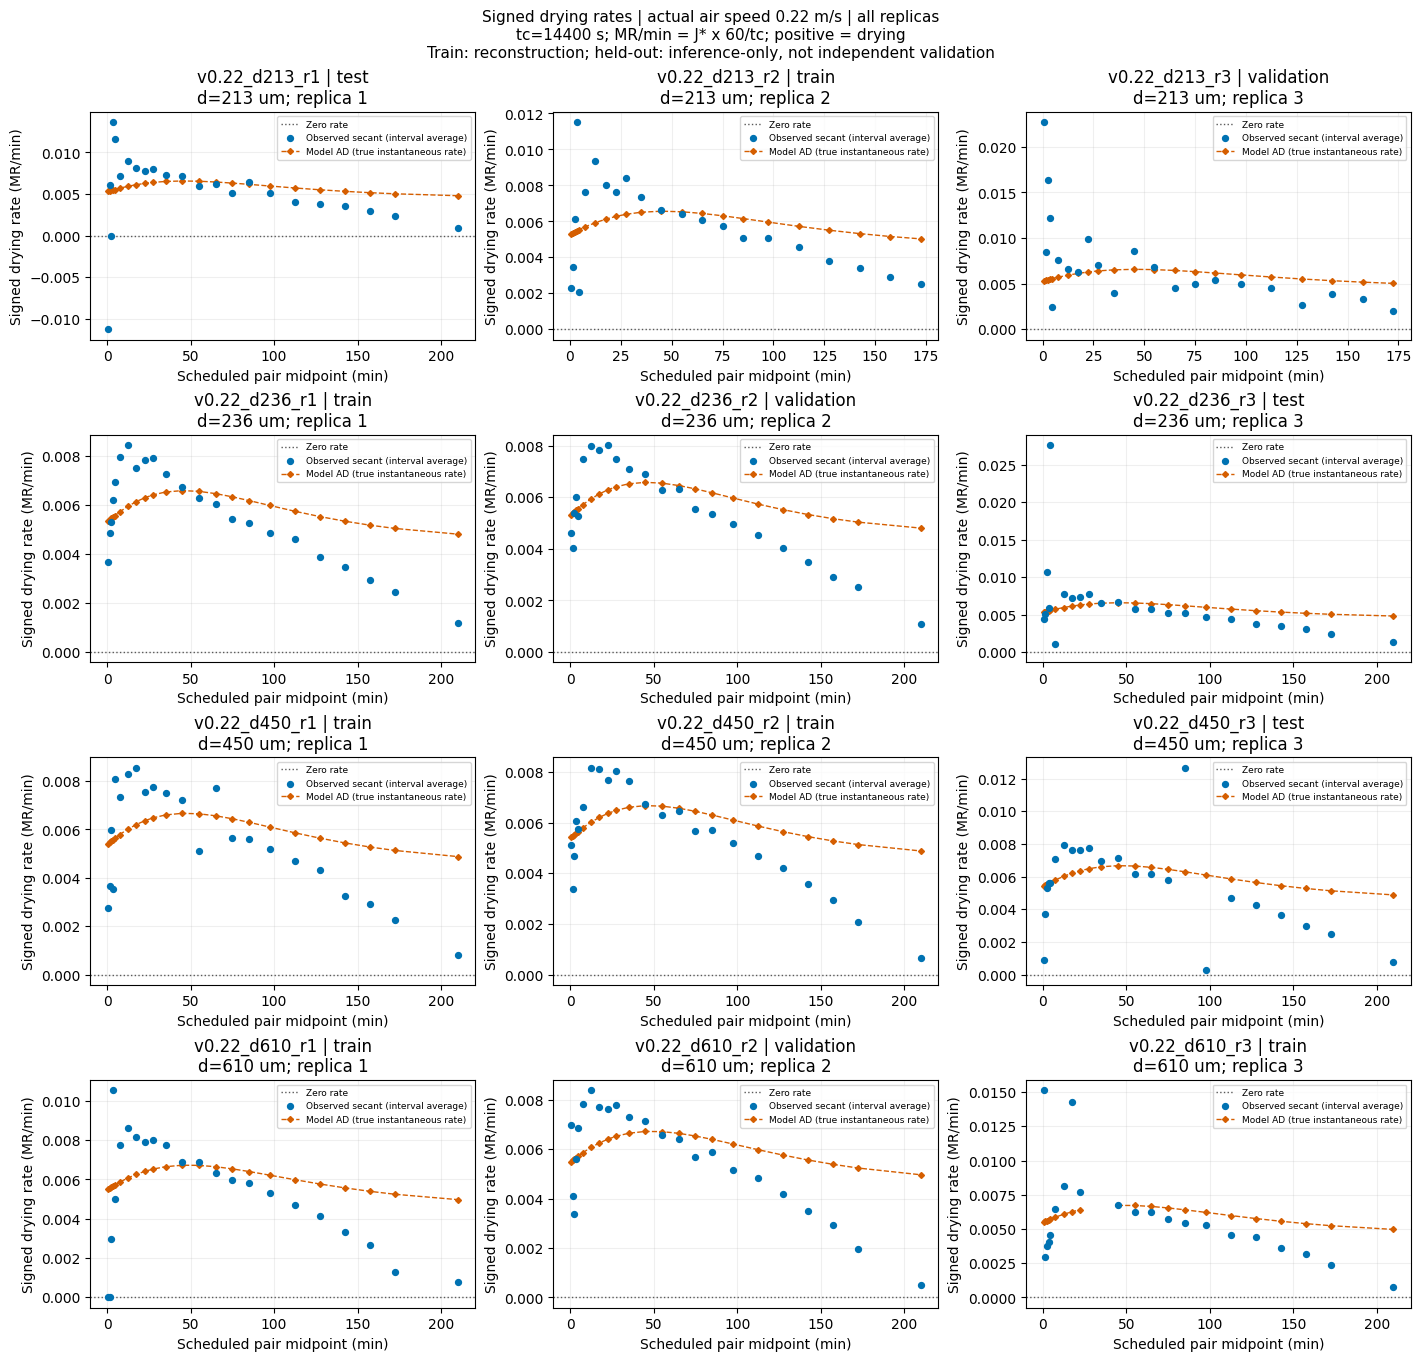

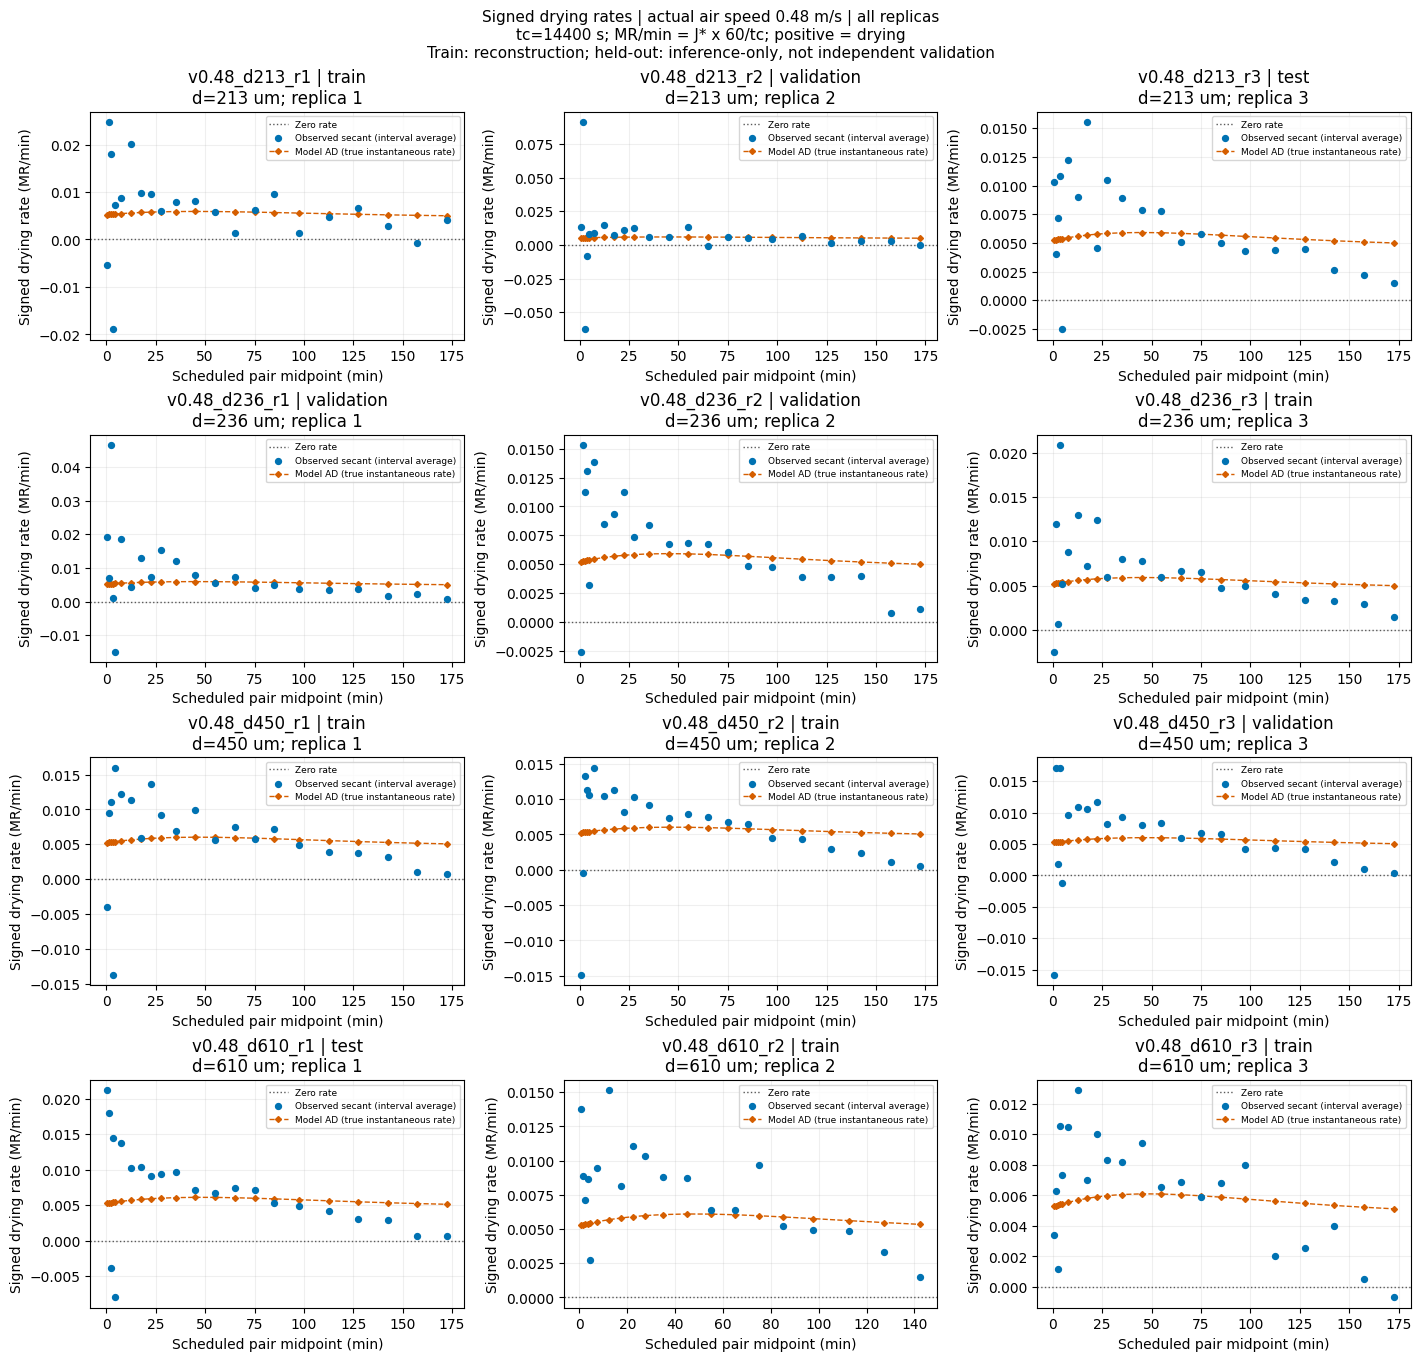

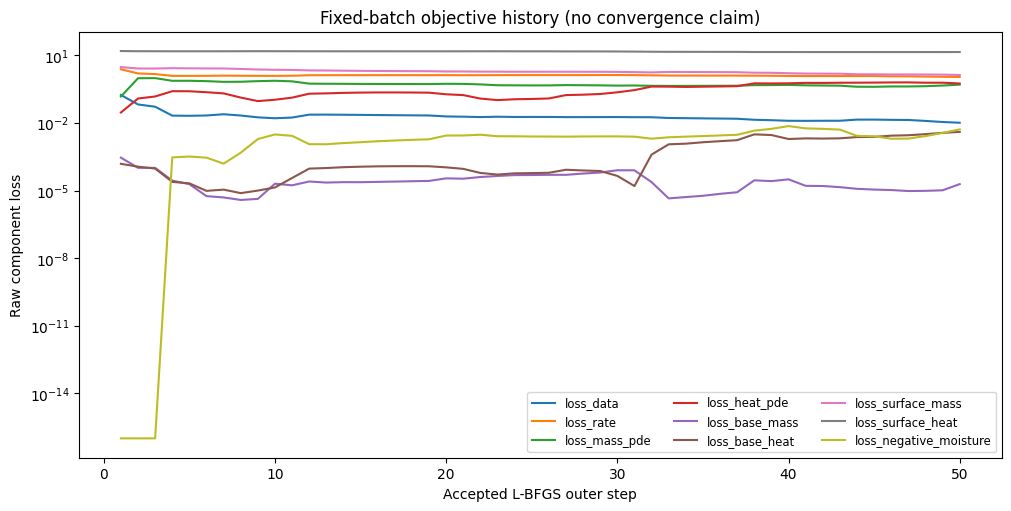

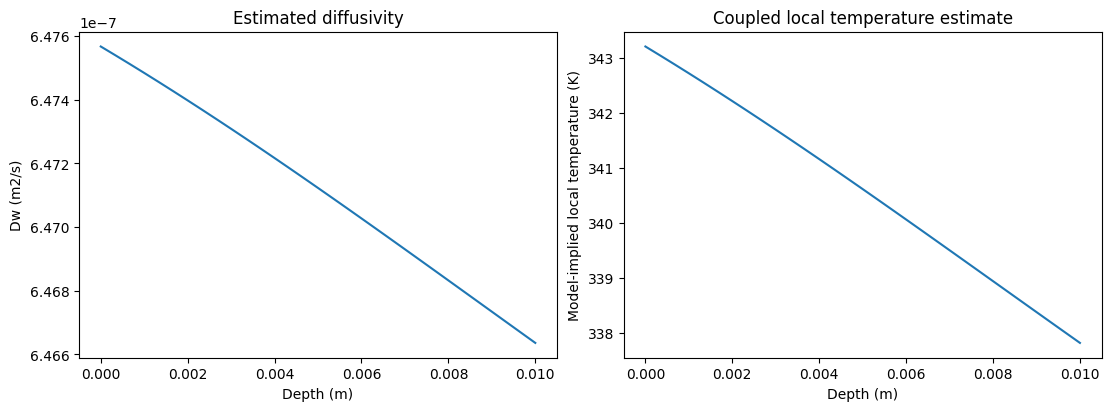

Fresh non-overwriting Strategy A run exported to: C:\Pasta_do_Jota\TCC\Modelling-coffee-drying\src\training_results\strategy_a_20261108_111505_095052


In [16]:
# Fail fast on an export request that has no trained estimate to publish.
validate_run_configuration(
    run_training=RUN_TRAINING, export_diffusivity=EXPORT_DIFFUSIVITY
)

# Split whole replicate curves before constructing their scheduled rate intervals.
# Only training curves supply measured-rate forcing; held-out curves are inference-only.
if len(experiments) < 3:
    raise ValueError("At least three replicate curves are needed for disjoint splits.")
curve_table = experiments.sort_values("experiment_id").reset_index(drop=True).copy()
permutation = np.random.default_rng(5).permutation(len(curve_table))
train_count = max(1, int(0.50 * len(curve_table)))
validation_count = max(1, int(0.30 * len(curve_table)))
if train_count + validation_count >= len(curve_table):
    validation_count = len(curve_table) - train_count - 1
split_names = np.full(len(curve_table), "test", dtype=object)
split_names[permutation[:train_count]] = "train"
split_names[permutation[train_count:train_count + validation_count]] = "validation"
curve_table["split"] = split_names
split_assignment = curve_table[["experiment_id", "split"]]

# Workbook excess-water mass divided by provisional bed volume gives Cw0 per run.
curve_table["initial_water_concentration_kg_m3"] = (
    curve_table["initial_sample_mass_kg"] - curve_table["dry_mass_kg"]
) / (math.pi * DISH_RADIUS_M**2 * BED_DEPTH_M)
physics_tables = build_physics_tables(curve_table, PHYSICAL_CONSTANTS)
training_curves = curve_table.loc[curve_table["split"].eq("train")].copy()
training_observations = observations.merge(
    split_assignment, on="experiment_id", validate="many_to_one"
).loc[lambda frame: frame["split"].eq("train")].drop(columns="split")
training_physics = physics_tables.loc[
    physics_tables["experiment_id"].isin(training_curves["experiment_id"])
].copy()
training_batch = build_training_batch(
    training_observations,
    training_curves,
    training_physics,
    collocation_count=COLLOCATION_COUNT,
    seed=TRAINING_SEED,
)

# Fixed batches, seeded initialization, and strong-Wolfe L-BFGS closures make
# repeated objective evaluations deterministic for this one inverse run.
torch.manual_seed(TRAINING_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(TRAINING_SEED)
model = DryingPINN()
if RUN_TRAINING:
    history, closure_evaluations, selected_outer_step = train_inverse_model(
        model, training_batch, steps=TRAINING_STEPS, learning_rate=0.001
    )
else:
    # Preprocessing-only mode: splits, physics groups and fixed batches are
    # built and inspectable, but the untrained model is never evaluated,
    # plotted or exported as if it were an estimate.
    print(
        "RUN_TRAINING=False: preprocessing and physics setup complete "
        f"({len(training_curves)} training curves, "
        f"{int(training_batch['rate_targets'].shape[0])} rate targets, "
        f"{int(training_batch['interior'].shape[0])} collocation points); "
        "skipped training, inference, plots and export."
    )


def bulk_predictions(frame: pd.DataFrame, state_model: DryingPINN) -> np.ndarray:
    """Predict depth-averaged moisture without applying measured boundary flux."""
    usable = frame.loc[frame["target_available"].fillna(False)].copy()
    usable["adm_recomputed"] = pd.to_numeric(usable["adm_recomputed"], errors="coerce")
    usable = usable.loc[np.isfinite(usable["adm_recomputed"])]
    if usable.empty:
        return np.empty((0,), dtype=float)
    merged = usable.merge(curve_table, on="experiment_id", validate="many_to_one")
    z_midpoints = np.linspace(0.5 / 50.0, 1.0 - 0.5 / 50.0, 50)
    predictions = []
    state_model.eval()
    with torch.no_grad():
        for row in merged.to_dict(orient="records"):
            features = _as_tensor(
                np.column_stack([
                    z_midpoints,
                    np.full(50, row["time_s"] / TIME_SCALE_S),
                    np.full(50, row["particle_diameter_m"] / DIAMETER_REFERENCE_M),
                    np.full(50, row["air_speed_m_s"] / SPEED_REFERENCE_M_S),
                ])
            )
            predictions.append(float(state_model(features)[:, 0].mean().cpu()))
    return np.asarray(predictions, dtype=float)


# Inference, diagnostics and plots require a model trained in this kernel.
if RUN_TRAINING:
    split_metrics = {}
    for split_name in ("train", "validation", "test"):
        split_observations = observations.merge(
            split_assignment, on="experiment_id", validate="many_to_one"
        ).loc[lambda frame: frame["split"].eq(split_name)]
        valid = split_observations.loc[
            split_observations["target_available"].fillna(False)
        ].copy()
        valid["adm_recomputed"] = pd.to_numeric(valid["adm_recomputed"], errors="coerce")
        valid = valid.loc[np.isfinite(valid["adm_recomputed"])]
        predictions = bulk_predictions(valid, model)
        if len(valid):
            weights = equal_curve_weights(valid, "experiment_id")
            residual = predictions - valid["adm_recomputed"].to_numpy(dtype=float)
            split_metrics[split_name] = float(np.sum(weights * residual**2))
        else:
            split_metrics[split_name] = None

    learned_parameters = format_learned_parameters(model)
    diffusivity_results = make_diffusivity_table(model, curve_table)
    print("\nJoint reconstruction estimates (not uniquely identified properties):")
    for parameter_name in ("theta0", "theta1", "theta2", "theta3"):
        print(f"  {parameter_name} = {learned_parameters[parameter_name]:.8g}")
    print("  D_w* equation:", learned_parameters["equation"])
    print(
        "  Activation-energy scale Ea=theta3*R*(Tair-T0) = "
        f"{learned_parameters['activation_energy_j_mol']:.8g} J/mol"
    )
    print(
        f"Accepted outer steps: {len(history)}; closure evaluations: "
        f"{closure_evaluations}; selected checkpoint: {selected_outer_step}"
    )
    print("Curve-weighted bulk MR MSE (monitoring only):", split_metrics)
    print("First diffusivity rows (temperature columns are model-implied):")
    display(diffusivity_results.head())

    # All-curve table remains inspectable, including source rows and signed
    # mass increases. Held-out predictions use no measured boundary forcing.
    drying_rate_table = make_drying_rate_table(model, observations, curve_table)
    print("Signed secants and bulk AD: MR/min = J* * 60 / tc; tc =", TIME_SCALE_S, "s")
    print("True bulk AD rate from the shared helper; no depth-count adjustment.")
    print("Historical runs optimized mis-scaled rate loss; corrected totals are a different objective.")
    print("All valid pairs are in drying_rate_table; train=reconstruction, held-out=inference-only.")
    display(drying_rate_table.head(10))
    display(curve_table.groupby(["air_speed_m_s", "split"]).size().unstack(fill_value=0))
    drying_rate_figures = plot_drying_rates(drying_rate_table, curve_table)
    plt.show()

    # Component losses and representative coupled state/diffusivity profiles are diagnostics.
    loss_columns = [column for column in history if column.startswith("loss_")]
    figure, axis = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for column in loss_columns:
        axis.semilogy(history["outer_step"], np.maximum(history[column], 1e-16), label=column)
    axis.set(xlabel="Accepted L-BFGS outer step", ylabel="Raw component loss")
    axis.set_title("Fixed-batch objective history (no convergence claim)")
    axis.legend(ncol=3, fontsize="small")
    plt.show()

    representative_id = training_curves.iloc[0]["experiment_id"]
    representative = diffusivity_results.loc[
        diffusivity_results["experiment_id"].eq(representative_id)
    ]
    latest_time = representative["time_star"].max()
    profile = representative.loc[np.isclose(representative["time_star"], latest_time)]
    figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    axes[0].plot(profile["depth_m"], profile["dw_m2_s"])
    axes[0].set(xlabel="Depth (m)", ylabel="Dw (m2/s)", title="Estimated diffusivity")
    axes[1].plot(profile["depth_m"], profile["temperature_k_model_implied"])
    axes[1].set(
        xlabel="Depth (m)", ylabel="Model-implied local temperature (K)",
        title="Coupled local temperature estimate",
    )
    plt.show()

# Redundant RUN_TRAINING guard keeps export safe even if validation changes.
if RUN_TRAINING and EXPORT_DIFFUSIVITY:
    output_name = "strategy_a_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    export_path = EXPORT_DIRECTORY / output_name
    group_records = [
        {
            key: (float(value) if isinstance(value, (np.floating, float)) else value)
            for key, value in record.items()
        }
        for record in physics_tables.to_dict(orient="records")
    ]
    manifest = {
        "purpose": "Coupled grey-box inverse reconstruction; not independent validation.",
        "physical_assumptions": {
            "bed_depth_m": BED_DEPTH_M,
            "provisional_dish_radius_m": DISH_RADIUS_M,
            "dish_diameter_m": DISH_DIAMETER_M,
            "t0_k": T0_K,
            "t_air_k": T_AIR_K,
            "latent_heat_j_kg": LATENT_HEAT_J_KG,
            "product_density_kg_m3": PRODUCT_DENSITY_KG_M3,
            "product_cp_j_kg_k": PRODUCT_CP_J_KG_K,
            "product_k_w_m_k": PRODUCT_K_W_M_K,
            "d_ref_m2_s": D_REF_M2_S,
            "time_scale_s": TIME_SCALE_S,
            "gamma": GAMMA,
            "air_property_temperature_k": AIR_PROPERTY_TEMPERATURE_K,
            "air_properties": {
                "mu_air_pa_s": MU_AIR_PA_S,
                "rho_air_kg_m3": RHO_AIR_KG_M3,
                "k_air_w_m_k": K_AIR_W_M_K,
                "cp_air_j_kg_k": CP_AIR_J_KG_K,
                "cp_interpolation": "linear 1007 at 320 K to 1009 at 340 K",
                "source_urls": AIR_PROPERTY_SOURCES,
            },
            "dimensionless_groups": {
                "fo_ref": FO_REF,
                "fo_heat": FO_HEAT,
                "per_curve_correlation_and_ev": group_records,
            },
            "convection_correlation": (
                "Re=v*D_dish/nu; Nu=0.664*sqrt(Re)*Pr^(1/3); "
                "h=Nu*k_air/D_dish; Bi=h*L/k_product"
            ),
            "comparison_values_only": {
                "user_h_w_m2_k": h,
                "user_bi": Bi,
                "bi_from_user_h_and_current_k_l": Bi,
            },
            "normalization": {
                "z_star": "depth / provisional 0.05 m",
                "t_star": "time / 14400 s",
                "rho_star": "local excess moisture / initial excess-water concentration",
                "temperature_star": "(T-T0)/(Tair-T0)",
                "d_star": "particle diameter / 450 um",
                "v_star": "air velocity / 0.22 m/s",
                "initial_water_concentration": "(initial wet mass - dry mass)/(pi*radius^2*bed depth)",
            },
        },
        "optimizer": {
            "name": "torch.optim.LBFGS",
            "outer_steps_requested": TRAINING_STEPS,
            "outer_steps_accepted": len(history),
            "closure_evaluations": closure_evaluations,
            "learning_rate": 0.001,
            "max_iter": 1,
            "line_search": "strong_wolfe",
            "fixed_collocation_count": COLLOCATION_COUNT,
            "seed": TRAINING_SEED,
            "selected_by": "minimum finite weighted training objective",
        },
        "split_counts": {
            str(key): int(value)
            for key, value in curve_table["split"].value_counts().items()
        },
        "bulk_mr_mse_monitoring_only": split_metrics,
        "limitations": [
            "Reconstruction estimates are not independently validated transport properties.",
            "Moisture-only data do not establish unique diffusivity or local-temperature identification.",
            "Depth and radius are provisional; model-implied temperatures are not measured temperatures.",
            "Measured interval secants approximate interval-average mass flux and retain negative rates.",
            "The flat-plate correlation is a simplifying external-transfer approximation for a dish.",
            "A bounded smoke run is not evidence of convergence or identifiability.",
        ],
    }
    exported_run = export_strategy_a_run(
        model=model,
        history=history,
        diffusivity_tables=diffusivity_results,
        output_path=export_path,
        manifest=manifest,
        selected_outer_step=selected_outer_step,
    )
    print("Fresh non-overwriting Strategy A run exported to:", exported_run)
